# Mass Spectrometry Imaging (MSI) Preprocessing & Analysis in Python

A hands-on computational pipeline for parsing `.imzML` datasets, performing spectral baseline correction, smoothing, peak centroiding, consensus $m/z$ alignment, and generating spatial ion distribution maps.

## 1. Loading `.imzML` Data & Inspecting Spatial Coordinates
Initialize `ImzMLParser`, inspect pixel grid dimensions, and plot a raw mass spectrum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pyimzml.ImzMLParser import ImzMLParser
f_path = "example.imzML"
parser = ImzMLParser(f_path)

C:\Users\arths\anaconda3\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000563 found with incorrect name "Thermo RAW file". Updating name to "Thermo RAW format".
  warn(
C:\Users\arths\anaconda3\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000590 found with incorrect name "contact organization". Updating name to "contact affiliation".
  warn(
C:\Users\arths\anaconda3\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000042 found with incorrect name "max count of pixel x". Updating name to "max count of pixels x".
  warn(
C:\Users\arths\anaconda3\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000043 found with incorrect name "max count of pixel y". Updating name to "max count of pixels y".
  warn(


In [16]:
coordinates = parser.coordinates
coordinates[-1]

(260, 134, 1)

In [115]:
max_x = max(c[0] for c in coordinates)
max_y = max(c[1] for c in coordinates)
print(f"Dataset Loaded. Image Matrix Dimensions: {max_x} x {max_y}")
print(f"Total Profiles/Pixels: {len(coordinates)}")

Dataset Loaded. Image Matrix Dimensions: 260 x 134
Total Profiles/Pixels: 34840


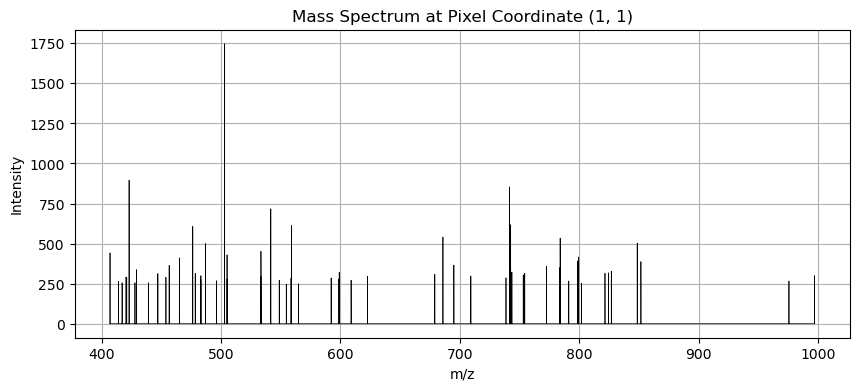

In [49]:
mzs, intensities = parser.getspectrum(33333)
plt.figure(figsize=(10, 4))
plt.plot(mzs, intensities, color='black', linewidth=0.5)
plt.title(f"Mass Spectrum at Pixel Coordinate {coordinates[0][:2]}")
plt.xlabel("m/z")
plt.ylabel("Intensity")
plt.grid(True)
plt.show()

## 2. Single-Ion Spatial Distribution Mapping (±10 ppm Window)
Extract pixel intensities around a target $m/z$ (`798.54 Da`) within a $\pm 10\text{ ppm}$ mass accuracy window and reconstruct the 2D spatial ion image.

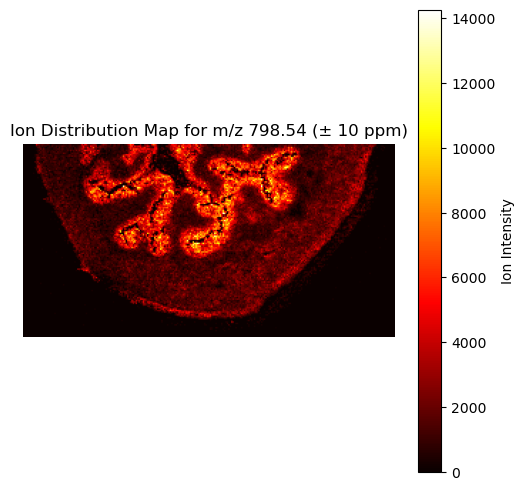

In [116]:
target_mz = 798.54  # Example target m/z (e.g., a specific phospholipid)
ppm_tolerance = 10  # Mass accuracy filter window in Parts Per Million

def calculate_tolerance(mz, ppm):
    return mz * (ppm / 1e6)

# Initialize a blank image grid
ion_image = np.zeros((max_y + 1, max_x + 1)) 

tol = calculate_tolerance(target_mz, ppm_tolerance)
mz_low = target_mz - tol
mz_high = target_mz + tol

# Iterate through all spectrum coordinates efficiently
for idx, (x, y, z) in enumerate(coordinates):
    pixel_mzs, pixel_ints = parser.getspectrum(idx)
    
    # Slice arrays via boolean mask to find peaks within the ppm window
    mask = (pixel_mzs >= mz_low) & (pixel_mzs <= mz_high)
    
    if np.any(mask):
        # Assign the maximum intensity peak found in that range to the coordinate
        ion_image[y, x] = np.max(pixel_ints[mask])

# 5. Plot the Mass Spec Image Spatial Map
plt.figure(figsize=(6, 6))
plt.imshow(ion_image, cmap='hot', origin='lower')
plt.colorbar(label='Ion Intensity')
plt.title(f"Ion Distribution Map for m/z {target_mz} (± {ppm_tolerance} ppm)")
plt.axis('off')
plt.show()

## 3. Baseline Correction via Asymmetric Least Squares (AsLS)
Remove low-frequency chemical matrix background noise across all pixel spectra using `pybaselines.Baseline.asls`, then compare raw vs. baseline-corrected spectra and ion images.

In [117]:
!pip install pybaselines
from pybaselines import Baseline

In [136]:
corrected_spectra = {}

for index, coord in enumerate(coordinates):

    mz, intensities = parser.getspectrum(index)

    if len(intensities) == 0:
        continue

    baseline_fitter = Baseline()

    baseline, _ = baseline_fitter.asls(
        intensities,
        lam=1e5,
        p=0.01
    )

    corrected_intensities = np.clip(
        intensities - baseline,
        0,
        None
    )

    x, y, z = coord

    corrected_spectra[(x, y)] = {
        "mz": mz,
        "intensities": corrected_intensities
    }

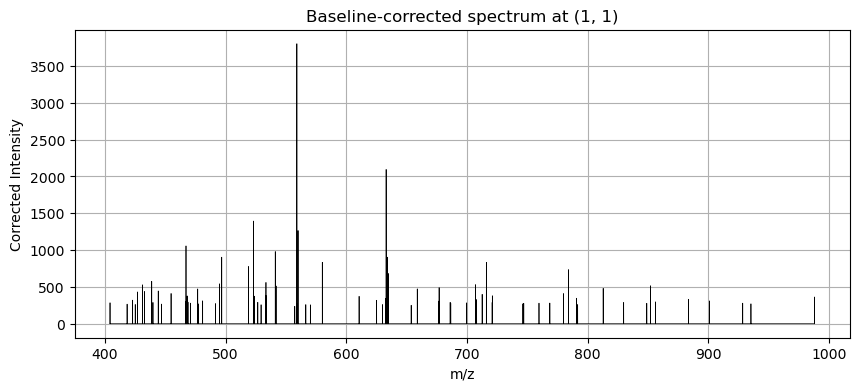

In [143]:
x, y = 1, 1  # choose a pixel

mz = corrected_spectra[(x, y)]["mz"]
intensities = corrected_spectra[(x, y)]["intensities"]

plt.figure(figsize=(10, 4))
plt.plot(mz, intensities,color='black', linewidth=0.5)
plt.xlabel("m/z")
plt.ylabel("Corrected Intensity")
plt.title(f"Baseline-corrected spectrum at ({x}, {y})")
plt.grid(True)

plt.show()



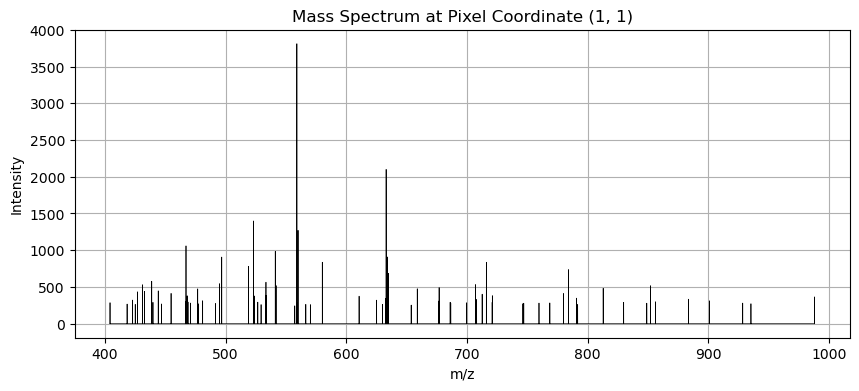

In [141]:
mzs, intensities = parser.getspectrum(0)
plt.figure(figsize=(10, 4))
plt.plot(mzs, intensities, color='black', linewidth=0.5)
plt.title(f"Mass Spectrum at Pixel Coordinate {coordinates[0][:2]}")
plt.xlabel("m/z")
plt.ylabel("Intensity")
plt.grid(True)
plt.show()

In [144]:
target_mz = 798.54
ppm_tolerance = 10

tol = target_mz * ppm_tolerance / 1e6
mz_low = target_mz - tol
mz_high = target_mz + tol

ion_image = np.zeros((max_y + 1, max_x + 1))

for index, (x, y, z) in enumerate(coordinates):

    mz = corrected_spectra[(x, y)]["mz"]
    intensities = corrected_spectra[(x, y)]["intensities"]

    mask = (mz >= mz_low) & (mz <= mz_high)

    if np.any(mask):
        ion_image[y, x] = np.max(intensities[mask])

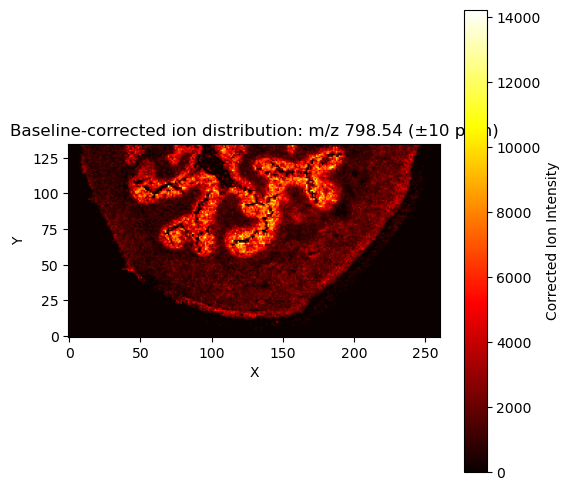

In [146]:
plt.figure(figsize=(6, 6))

plt.imshow(
    ion_image,
    origin="lower",
    cmap="hot"
)

plt.colorbar(label="Corrected Ion Intensity")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Baseline-corrected ion distribution: m/z 798.54 (±10 ppm)")

plt.show()

## 4. Spectral Smoothing & Peak Picking (Centroiding)
Apply Savitzky–Golay smoothing (`savgol_filter`), detect peaks (`find_peaks`), convert profile spectra to centroid peaks, and compare raw vs. centroided ion distribution maps side by side.

In [182]:
from scipy.signal import savgol_filter, find_peaks
smoothed_intensity = savgol_filter(intensities, window_length=11, polyorder=3)

In [184]:
peak_indices, properties = find_peaks(smoothed_intensity, prominence=100)
centroid_mz = mz[peak_indices]
centroid_intensity = smoothed_intensity[peak_indices]

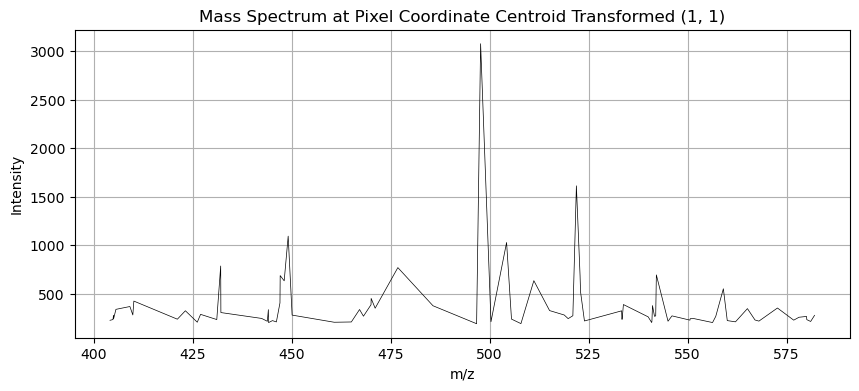

In [189]:
plt.figure(figsize=(10, 4))
plt.plot(centroid_mz, centroid_intensity, color='black', linewidth=0.5)
plt.title(f"Mass Spectrum at Pixel Coordinate Centroid Transformed {coordinates[0][:2]}")
plt.xlabel("m/z")
plt.ylabel("Intensity")
plt.grid(True)
plt.show()

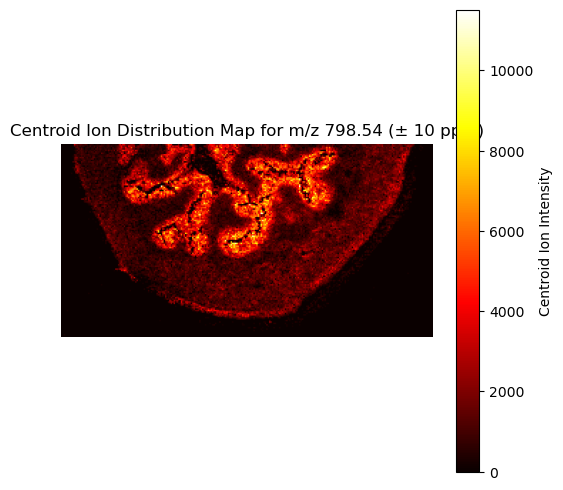

In [190]:
max_x = max(c[0] for c in coordinates)
max_y = max(c[1] for c in coordinates)
target_mz = 798.54
ppm_tolerance = 10
def calculate_tolerance(mz, ppm):
    return mz * (ppm / 1e6)
ion_image = np.zeros((max_y + 1, max_x + 1))
tol = calculate_tolerance(target_mz, ppm_tolerance)
mz_low = target_mz - tol
mz_high = target_mz + tol
for idx, (x, y, z) in enumerate(coordinates):
    pixel_mzs, pixel_ints = parser.getspectrum(idx)
    if len(pixel_ints) == 0:
        continue
    if len(pixel_ints) < 11:
        continue
    smoothed_intensity = savgol_filter(
        pixel_ints,
        window_length=11,
        polyorder=3
    )
    peak_indices, properties = find_peaks(
        smoothed_intensity,
        prominence=100
    )
    centroid_mz = pixel_mzs[peak_indices]
    centroid_intensity = smoothed_intensity[peak_indices]
    mask = (
        (centroid_mz >= mz_low) &
        (centroid_mz <= mz_high)
    )
    if np.any(mask):
        ion_image[y, x] = np.max(centroid_intensity[mask])


plt.figure(figsize=(6, 6))

plt.imshow(
    ion_image,
    cmap='hot',
    origin='lower')
plt.colorbar(label='Centroid Ion Intensity')

plt.title(
    f'Centroid Ion Distribution Map for '
    f'm/z {target_mz} (± {ppm_tolerance} ppm)')

plt.axis('off')
plt.show()

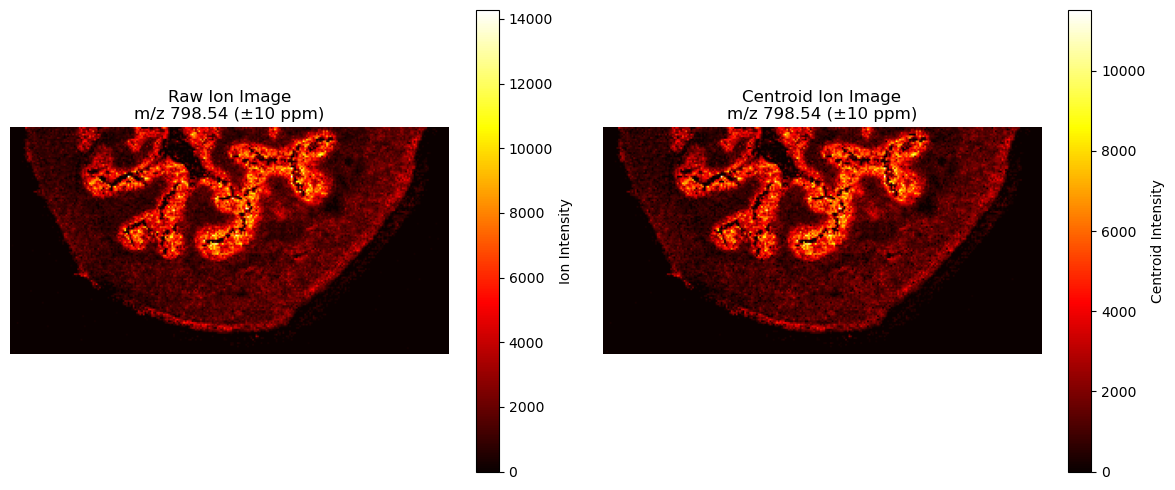

In [191]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks

target_mz = 798.54
ppm_tolerance = 10

def calculate_tolerance(mz, ppm):
    return mz * (ppm / 1e6)

max_x = max(c[0] for c in coordinates)
max_y = max(c[1] for c in coordinates)

# Create two image grids
ion_image = np.zeros((max_y + 1, max_x + 1))
centroid_ion_image = np.zeros((max_y + 1, max_x + 1))

tol = calculate_tolerance(target_mz, ppm_tolerance)
mz_low = target_mz - tol
mz_high = target_mz + tol


for idx, (x, y, z) in enumerate(coordinates):

    pixel_mzs, pixel_ints = parser.getspectrum(idx)

    if len(pixel_ints) == 0:
        continue

    # --------------------------------------------------
    # 1. RAW DATA ION IMAGE
    # --------------------------------------------------

    mask = (
        (pixel_mzs >= mz_low) &
        (pixel_mzs <= mz_high)
    )

    if np.any(mask):
        ion_image[y, x] = np.max(pixel_ints[mask])


    # --------------------------------------------------
    # 2. CENTROID DATA ION IMAGE
    # --------------------------------------------------

    # Need enough points for Savitzky-Golay filter
    if len(pixel_ints) < 11:
        continue

    # Smooth spectrum
    smoothed_intensity = savgol_filter(
        pixel_ints,
        window_length=11,
        polyorder=3
    )

    # Detect peaks
    peak_indices, properties = find_peaks(
        smoothed_intensity,
        prominence=100
    )

    # Convert to centroid spectrum
    centroid_mz = pixel_mzs[peak_indices]
    centroid_intensity = smoothed_intensity[peak_indices]

    # Find centroid peaks in target window
    centroid_mask = (
        (centroid_mz >= mz_low) &
        (centroid_mz <= mz_high)
    )

    if np.any(centroid_mask):
        centroid_ion_image[y, x] = np.max(
            centroid_intensity[centroid_mask]
        )


# --------------------------------------------------
# PLOT BOTH IMAGES SIDE BY SIDE
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# Raw ion image
im1 = axes[0].imshow(
    ion_image,
    cmap='hot',
    origin='lower'
)

axes[0].set_title(
    f"Raw Ion Image\nm/z {target_mz} (±{ppm_tolerance} ppm)"
)

axes[0].axis('off')

fig.colorbar(
    im1,
    ax=axes[0],
    label='Ion Intensity'
)


# Centroid ion image
im2 = axes[1].imshow(
    centroid_ion_image,
    cmap='hot',
    origin='lower'
)

axes[1].set_title(
    f"Centroid Ion Image\nm/z {target_mz} (±{ppm_tolerance} ppm)"
)

axes[1].axis('off')

fig.colorbar(
    im2,
    ax=axes[1],
    label='Centroid Intensity'
)


plt.tight_layout()
plt.show()

## 5. Consensus $m/z$ Alignment & Sparse Feature Matrix Construction
Aggregate centroided peaks across all pixels into a `0.005 Da` consensus $m/z$ grid, align each pixel's peaks within $\pm 5\text{ ppm}$ using `np.searchsorted`, store the resulting matrix in `scipy.sparse.csr_matrix` format, and reconstruct spatial maps from the aligned matrix.

In [193]:
from scipy.signal import find_peaks, savgol_filter
from scipy.sparse import lil_matrix

In [194]:
all_centroid_mz = []
all_centroid_intensities = []
pixel_coordinates = []
for i, (x, y, z) in enumerate(parser.coordinates):
    mz_array, intensity_array = parser.getspectrum(i)
    
    # Apply smoothing and centroiding
    smoothed_intensity = savgol_filter(intensity_array, window_length=11, polyorder=3)
    peak_indices, _ = find_peaks(smoothed_intensity, prominence=100)
    
    # Store the discrete peaks
    all_centroid_mz.append(mz_array[peak_indices])
    all_centroid_intensities.append(smoothed_intensity[peak_indices])
    pixel_coordinates.append((x, y))

In [230]:
master_mz_array = np.concatenate(all_centroid_mz)
min_mz = np.floor(np.min(master_mz_array))
max_mz = np.ceil(np.max(master_mz_array))
bin_width = 0.005  # 0.005 Da resolution grid
bins = np.arange(min_mz, max_mz, bin_width)
histogram_counts, bin_edges = np.histogram(master_mz_array, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
consensus_indices, _ = find_peaks(histogram_counts, height=10)
consensus_mz = bin_centers[consensus_indices]
num_pixels = len(pixel_coordinates)
num_features = len(consensus_mz)
ppm_tolerance = 5.0
feature_matrix = lil_matrix((num_pixels, num_features), dtype=np.float32)

for i in range(num_pixels):
    pixel_mz = all_centroid_mz[i]
    pixel_intensity = all_centroid_intensities[i]
    
    # Quickly find the index of the nearest consensus mass for every peak
    closest_indices = np.searchsorted(consensus_mz, pixel_mz)
    
    # Handle array boundaries in case a peak is slightly larger than the max consensus mass
    closest_indices = np.clip(closest_indices, 0, num_features - 1)
    
    # Calculate the exact parts-per-million (PPM) distance
    target_mz = consensus_mz[closest_indices]
    mass_error_ppm = np.abs(pixel_mz - target_mz) / target_mz * 1e6
    
    # Create a boolean filter for peaks that fall strictly within the tolerance
    valid_mask = mass_error_ppm <= ppm_tolerance
    
    # Assign the intensities to the correct columns in the matrix
    valid_features = closest_indices[valid_mask]
    valid_intensities = pixel_intensity[valid_mask]
    
    feature_matrix[i, valid_features] = valid_intensities

# Step 5: Convert to CSR format for fast mathematical operations in downstream ML tasks
feature_matrix = feature_matrix.tocsr()

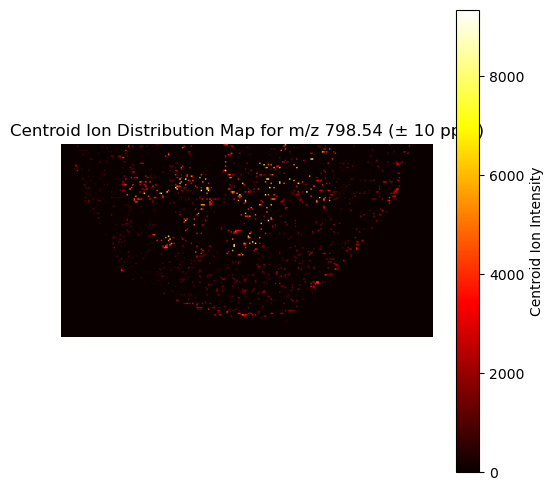

In [271]:
# --------------------------------------------------
# Extract intensities from the feature matrix
# --------------------------------------------------

if len(matching_features) == 0:

    print("No consensus features found in the target m/z window.")

else:

    target_intensities = feature_matrix[:, matching_features]

    # Maximum intensity across matching m/z features
    ion_intensities = (
        target_intensities
        .max(axis=1)
        .toarray()
        .ravel()
    )

    # --------------------------------------------------
    # Reconstruct spatial image
    # --------------------------------------------------

    max_x = max(c[0] for c in coordinates)
    max_y = max(c[1] for c in coordinates)

    ion_image = np.zeros(
        (max_y + 1, max_x + 1)
    )

    for i, (x, y, z) in enumerate(coordinates):
        ion_image[y, x] = ion_intensities[i]

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(figsize=(6, 6))

    plt.imshow(
        ion_image,
        cmap='hot',
        origin='lower'
    )

    plt.colorbar(
        label='Centroid Ion Intensity'
    )

    plt.title(
        f'Centroid Ion Distribution Map for '
        f'm/z {target_mz} (± {ppm_tolerance} ppm)'
    )

    plt.axis('off')
    plt.show()


## 6. Dataset Diagnostics: Continuous vs. Processed Mode & TIC Map
Inspect dataset acquisition mode (continuous vs. processed $m/z$ axes), compute a Total Ion Current (TIC) grid, and visualize integrated ion intensity alongside its non-zero pixel distribution histogram.

In [42]:
from pyimzml.ImzMLParser import ImzMLParser
import numpy as np
import matplotlib.pyplot as plt
def inspect_msi_dataset(imzml_path):
    parser = ImzMLParser(imzml_path)
    coords = parser.coordinates
    n_pixels = len(coords)
    xs = [c[0] for c in coords]
    ys = [c[1] for c in coords]
    max_x, max_y = max(xs), max(ys)
    # Inspect first and second pixel to check if m/z axis is identical (Continuousvs Processed)
    mz_0, int_0 = parser.getspectrum(0)
    mz_1, int_1 = parser.getspectrum(1)
    is_continuous = (len(mz_0) == len(mz_1)) and np.allclose(mz_0, mz_1)
    print(f"Total Pixels: {n_pixels} | Grid Bounding Box: {max_x} x {max_y}")
    print(f"Spectrum 0 length: {len(mz_0)} bins | Continuous Mode:{is_continuous}")
    print(f"m/z Range: {mz_0.min():.4f} to {mz_0.max():.4f} Da")
    tic_grid = np.full((max_y, max_x), np.nan)
    for idx, (x, y, _) in enumerate(coords):
        _, intensities = parser.getspectrum(idx)
        tic_grid[y - 1, x - 1] = np.sum(intensities)
    return tic_grid, mz_0, int_0

tic_img, mz_vec, int_vec = inspect_msi_dataset("example.imzML")

Total Pixels: 34840 | Grid Bounding Box: 260 x 134
Spectrum 0 length: 1129 bins | Continuous Mode:False
m/z Range: 404.0927 to 988.2324 Da


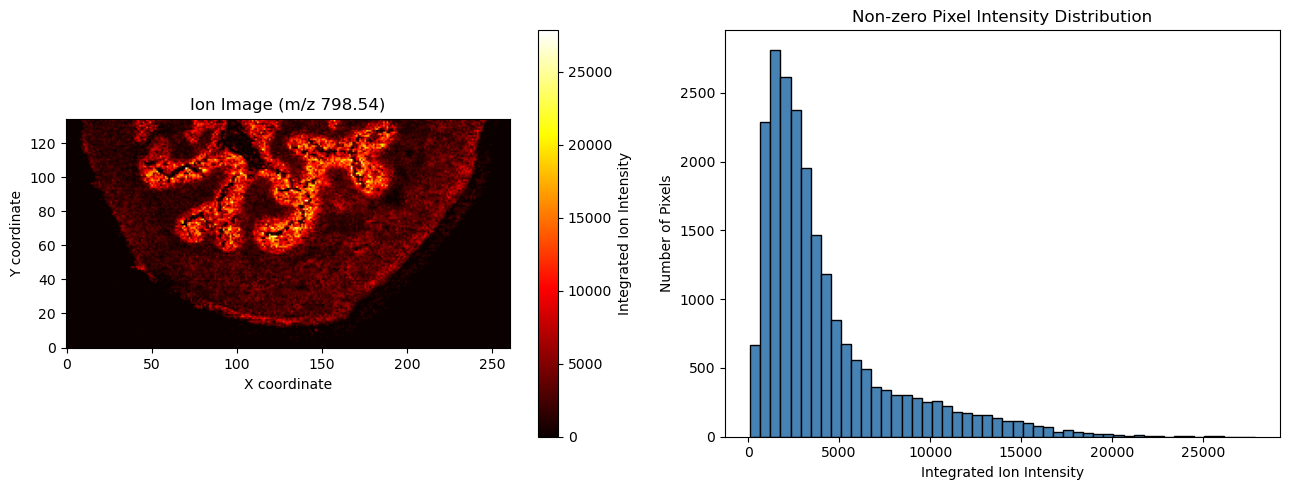

array([[  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   0.        , 505.91394043, ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       ...,
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ]])

In [81]:
def get_ion_image(parser, target_mz, ppm_tol=10):

    delta_m = target_mz * (ppm_tol * 10**(-6))

    mz_low = target_mz - delta_m
    mz_high = target_mz + delta_m

    ion_image = np.zeros((max_y + 1, max_x + 1))

    for idx, (x, y, z) in enumerate(coordinates):

        pixel_mzs, pixel_ints = parser.getspectrum(idx)

        mask = (pixel_mzs >= mz_low) & (pixel_mzs <= mz_high)

        if np.any(mask):
            ion_image[y, x] = np.sum(pixel_ints[mask])

    # Move this OUTSIDE the if statement and for loop
    nonzero_intensities = ion_image[ion_image > 0]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Spatial heatmap
    im = axes[0].imshow(
        ion_image,
        cmap='hot',
        origin='lower'
    )

    axes[0].set_title(f'Ion Image (m/z {target_mz})')
    axes[0].set_xlabel('X coordinate')
    axes[0].set_ylabel('Y coordinate')

    plt.colorbar(im, ax=axes[0], label='Integrated Ion Intensity')

    # Histogram
    axes[1].hist(
        nonzero_intensities,
        bins=50,
        color='steelblue',
        edgecolor='black'
    )

    axes[1].set_title('Non-zero Pixel Intensity Distribution')
    axes[1].set_xlabel('Integrated Ion Intensity')
    axes[1].set_ylabel('Number of Pixels')

    plt.tight_layout()
    plt.show()

    return ion_image


get_ion_image(parser, 798.54)

## 7. Alternative Preprocessing: Savitzky–Golay & 1D Morphological Top-Hat Baseline
Apply Savitzky–Golay smoothing and 1D morphological grey-opening (Top-Hat) baseline subtraction to inspect full and zoomed $m/z$ windows.

In [73]:
from scipy.signal import savgol_filter
for idx, (x, y, z) in enumerate(coordinates):
    mzs, intensities = parser.getspectrum(idx)
    smoothed_intensities = savgol_filter(
      intensities, window_length=5, polyorder=2
  )

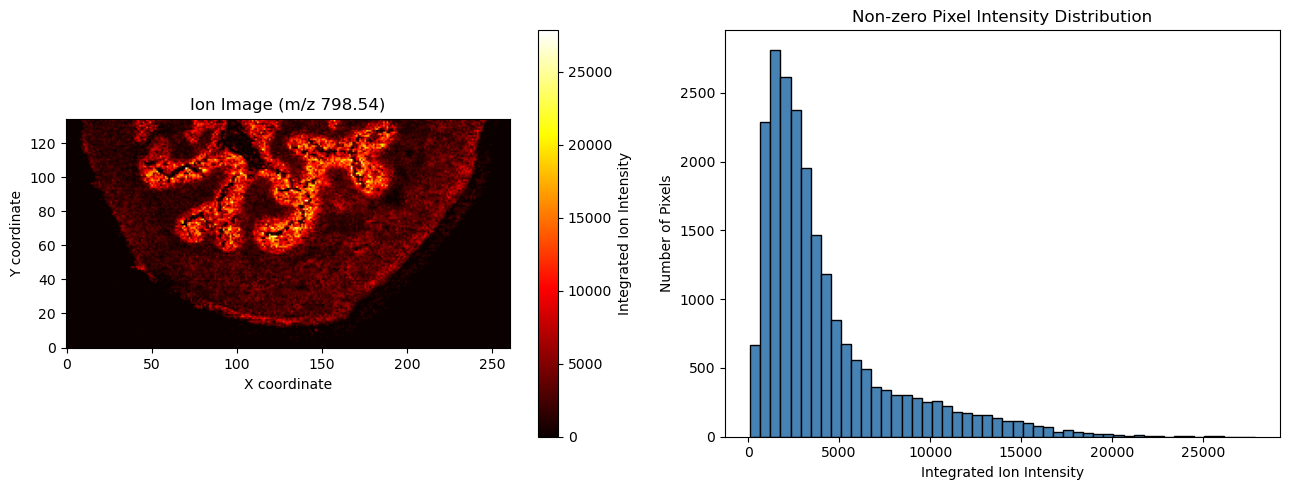

In [84]:
from skimage import morphology
ion_image = get_ion_image(parser, 798.54)

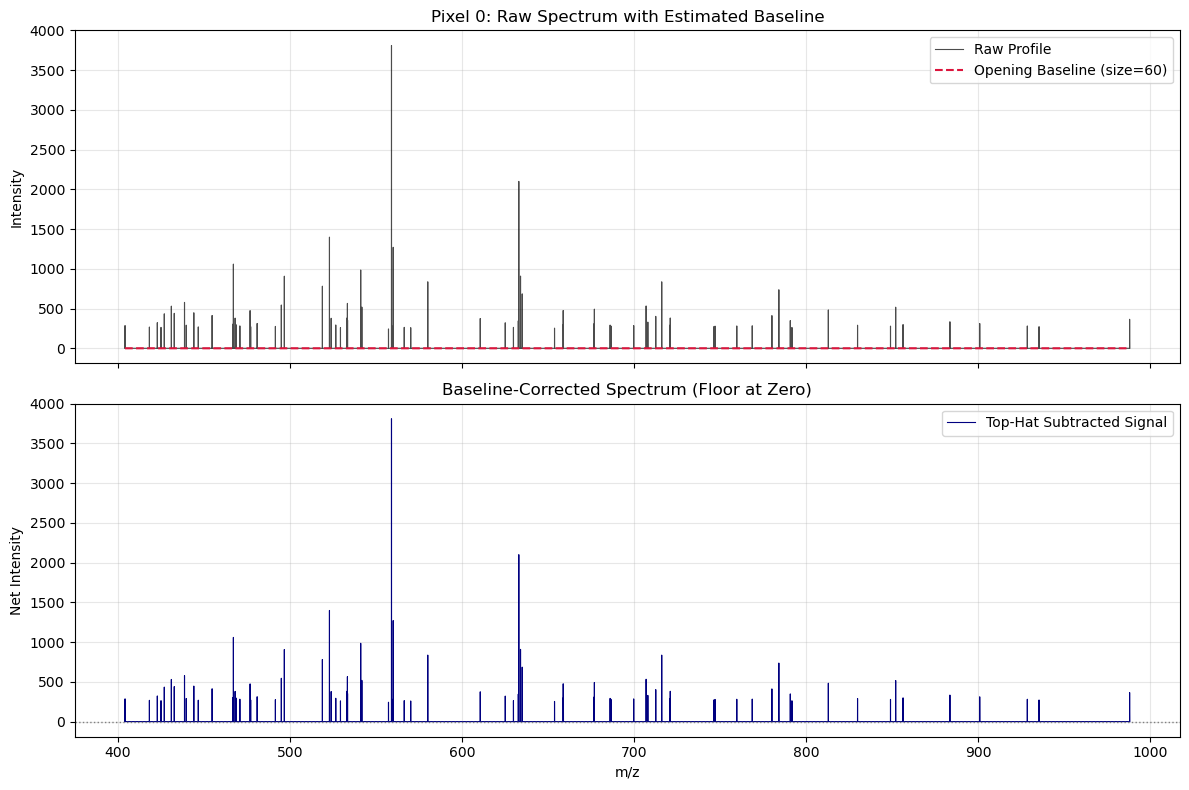

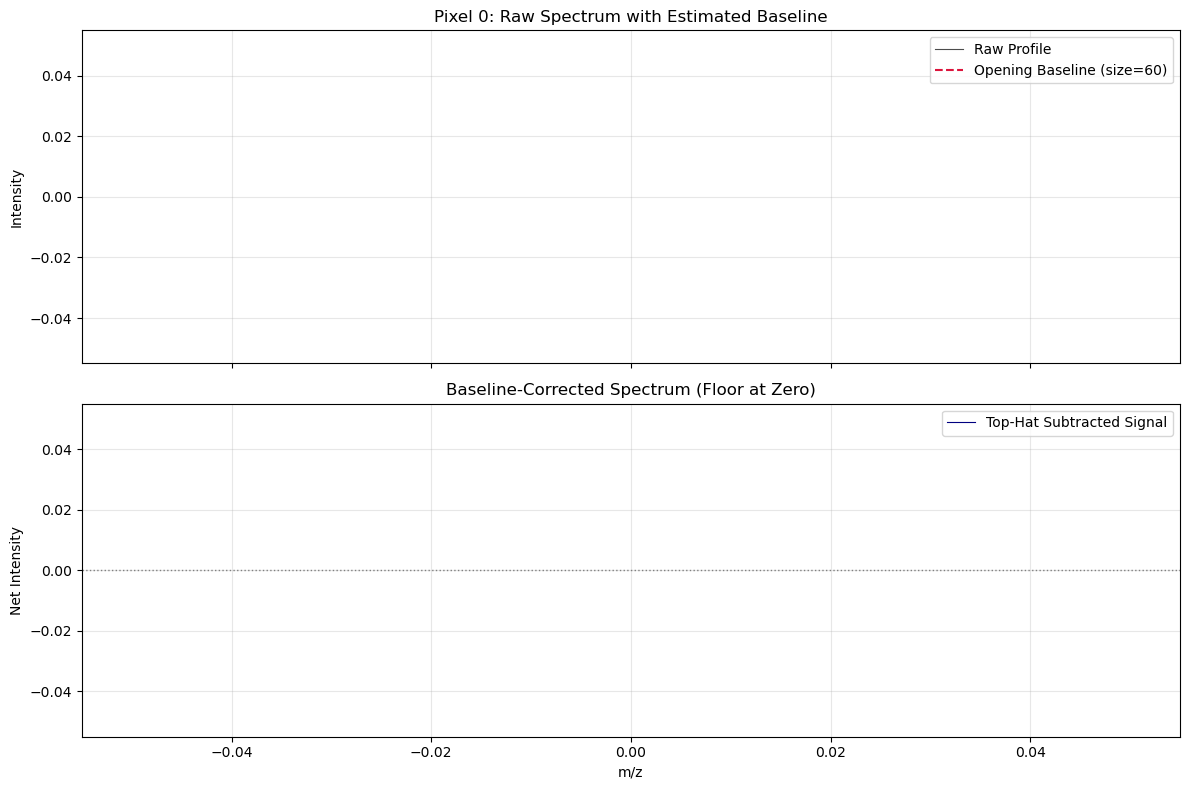

(array([0., 0., 0., ..., 0., 0., 0.], dtype=float32),
 array([0., 0., 0., ..., 0., 0., 0.], dtype=float32))

In [103]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import grey_opening, white_tophat


def inspect_spectral_tophat(
    parser, pixel_idx=0, structuring_size=50, mz_window=None
):
    mzs, raw_ints = parser.getspectrum(pixel_idx)

    if len(mzs) == 0:
        print(f'Pixel {pixel_idx} contains no spectral points.')
        return

    # Calculate baseline via morphological opening
    # The structuring element is a 1D line of length `structuring_size`
    baseline = grey_opening(raw_ints, size=structuring_size)

    # Top-hat is the raw signal minus the baseline
    corrected_ints = raw_ints - baseline

    # Optional zoom into a specific m/z window
    if mz_window is not None:
        low_mz, high_mz = mz_window
        mask = (mzs >= low_mz) & (mzs <= high_mz)
        plot_mzs = mzs[mask]
        plot_raw = raw_ints[mask]
        plot_base = baseline[mask]
        plot_corr = corrected_ints[mask]
    else:
        plot_mzs = mzs
        plot_raw = raw_ints
        plot_base = baseline
        plot_corr = corrected_ints

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Top plot: Raw spectrum with estimated baseline overlaid
    axes[0].plot(
        plot_mzs,
        plot_raw,
        color='black',
        lw=0.8,
        label='Raw Profile',
        alpha=0.7,
    )
    axes[0].plot(
        plot_mzs,
        plot_base,
        color='crimson',
        lw=1.5,
        linestyle='--',
        label=f'Opening Baseline (size={structuring_size})',
    )
    axes[0].set_title(f'Pixel {pixel_idx}: Raw Spectrum with Estimated Baseline')
    axes[0].set_ylabel('Intensity')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.3)

    # Bottom plot: Cleaned 1D Top-Hat result
    axes[1].plot(
        plot_mzs,
        plot_corr,
        color='navy',
        lw=0.8,
        label='Top-Hat Subtracted Signal',
    )
    axes[1].axhline(0, color='gray', linestyle=':', lw=1)
    axes[1].set_title('Baseline-Corrected Spectrum (Floor at Zero)')
    axes[1].set_xlabel('m/z')
    axes[1].set_ylabel('Net Intensity')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return corrected_ints, baseline


# Inspect the entire spectrum of pixel 0
# Adjust structuring_size to match roughly 1.5 to 2x the width of your broadest peak in channels
corrected, baseline = inspect_spectral_tophat(
    parser, pixel_idx=0, structuring_size=60
)

# Inspect a zoomed region around target m/z 798.54
inspect_spectral_tophat(
    parser, pixel_idx=0, structuring_size=60, mz_window=(795.0, 802.0)
)

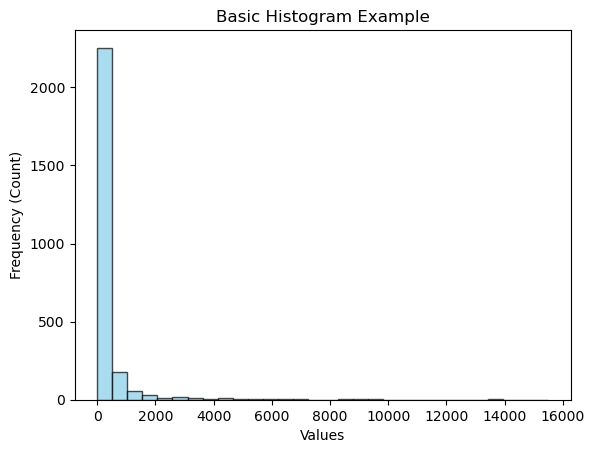

In [108]:
plt.hist(intensities, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.xlabel('Values')
plt.ylabel('Frequency (Count)')
plt.title('Basic Histogram Example')
plt.show()